In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import f_classif, mutual_info_classif, RFE
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
sns.set_theme(style="whitegrid")

# Práctica 2: Clasificación no temporal de diagnósticos
**Curso:** Inteligencia Artificial, semana 6, clase 6

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI (CC BY 4.0). 569 observaciones, 30 características, etiqueta M (maligno) / B (benigno).

> Uso exclusivamente educativo; los resultados no constituyen una herramienta clínica.

**Estructura del notebook**

Las secciones siguen las actividades de la guía y se agrupan en cuatro bloques:

| Bloque | Actividades de la guía |
|---|---|
| Exploración y preparación de datos | 1 (descarga y verificación), 5 (partición estratificada) y 1-2 (exploración y redundancia) |
| Selección de variables | 3 (técnicas de selección, estabilidad y subconjuntos candidatos) |
| Entrenamiento y validación de modelos | 4 (comparación con la misma arquitectura y particiones) |
| Evaluación final y conclusiones | 7 (lista final y justificación), 6 (evaluación en prueba) y conclusión |

**Métrica principal:** recall (sensibilidad) de la clase maligna. Un falso negativo, es decir, un tumor maligno clasificado como benigno, es el error más costoso, por lo que se prioriza por encima del accuracy.

## Actividad 1. Descarga y verificación de los datos
Se descargan los datos, se verifican las clases y los valores nulos y se excluye cualquier identificador (`ID`).

In [3]:
cancer = fetch_ucirepo(id=17)
X = cancer.data.features.copy()
X = X.drop(columns=["ID"], errors="ignore")      # sin identificadores
y = cancer.data.targets.squeeze().map({"B": 0, "M": 1})

print(X.shape)
print(y.value_counts())
print("Nulos:", int(X.isna().sum().sum()))
display(X.head())

(569, 30)
Diagnosis
0    357
1    212
Name: count, dtype: int64
Nulos: 0


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Actividad 5. Partición estratificada
Prueba final estratificada (20 %) y validación estratificada dentro del conjunto de desarrollo (25 %), lo que da una división 60 / 20 / 20. El escalado y la selección se ajustan solo con entrenamiento.

In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

for nombre, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{nombre}: {len(yy)} muestras | malignos: {yy.mean():.2%}")

Train: 341 muestras | malignos: 37.24%
Val: 114 muestras | malignos: 37.72%
Test: 114 muestras | malignos: 36.84%


## Actividades 1 y 2. Exploración: clases, escalas, correlaciones y redundancia
Escalado y selección se ajustan únicamente con `X_train`.

### 2.1 Clases y escalas (Actividad 1)

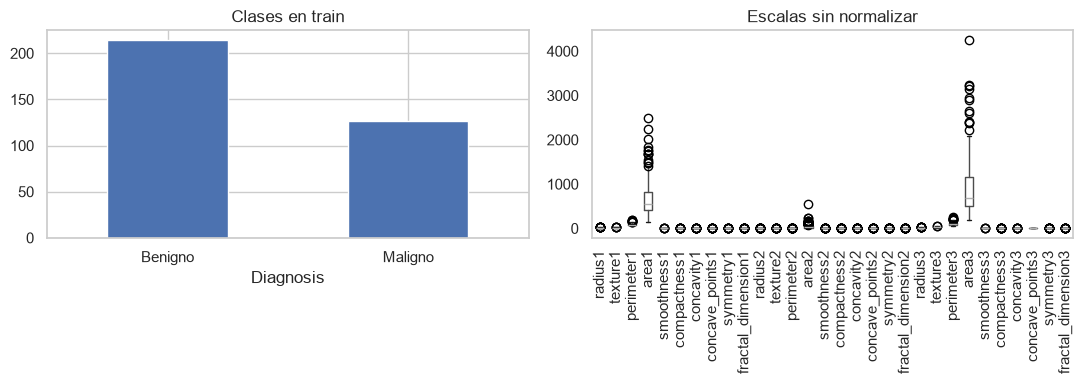

,mean,std,min,max
radius1,14.163419,3.599320,6.981000,27.42000
texture1,19.428768,4.361160,9.710000,39.28000
perimeter1,92.172581,24.857806,43.790000,186.90000
area1,659.691789,360.073150,143.500000,2501.00000
smoothness1,0.095654,0.014271,0.064290,0.16340
compactness1,0.103103,0.053278,0.023440,0.34540
concavity1,0.087244,0.078981,0.000000,0.42680
concave_points1,0.048194,0.039362,0.000000,0.20120
symmetry1,0.180586,0.027461,0.106000,0.30400
fractal_dimension1,0.062508,0.006797,0.050240,0.09744


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y_train.map({0: "Benigno", 1: "Maligno"}).value_counts().plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Clases en train")
X_train.boxplot(ax=ax[1], rot=90, grid=False)
ax[1].set_title("Escalas sin normalizar")
plt.tight_layout(); plt.show()

display(X_train.describe().T[["mean", "std", "min", "max"]])

### 2.2 Correlaciones entre las 30 variables (Actividad 1)

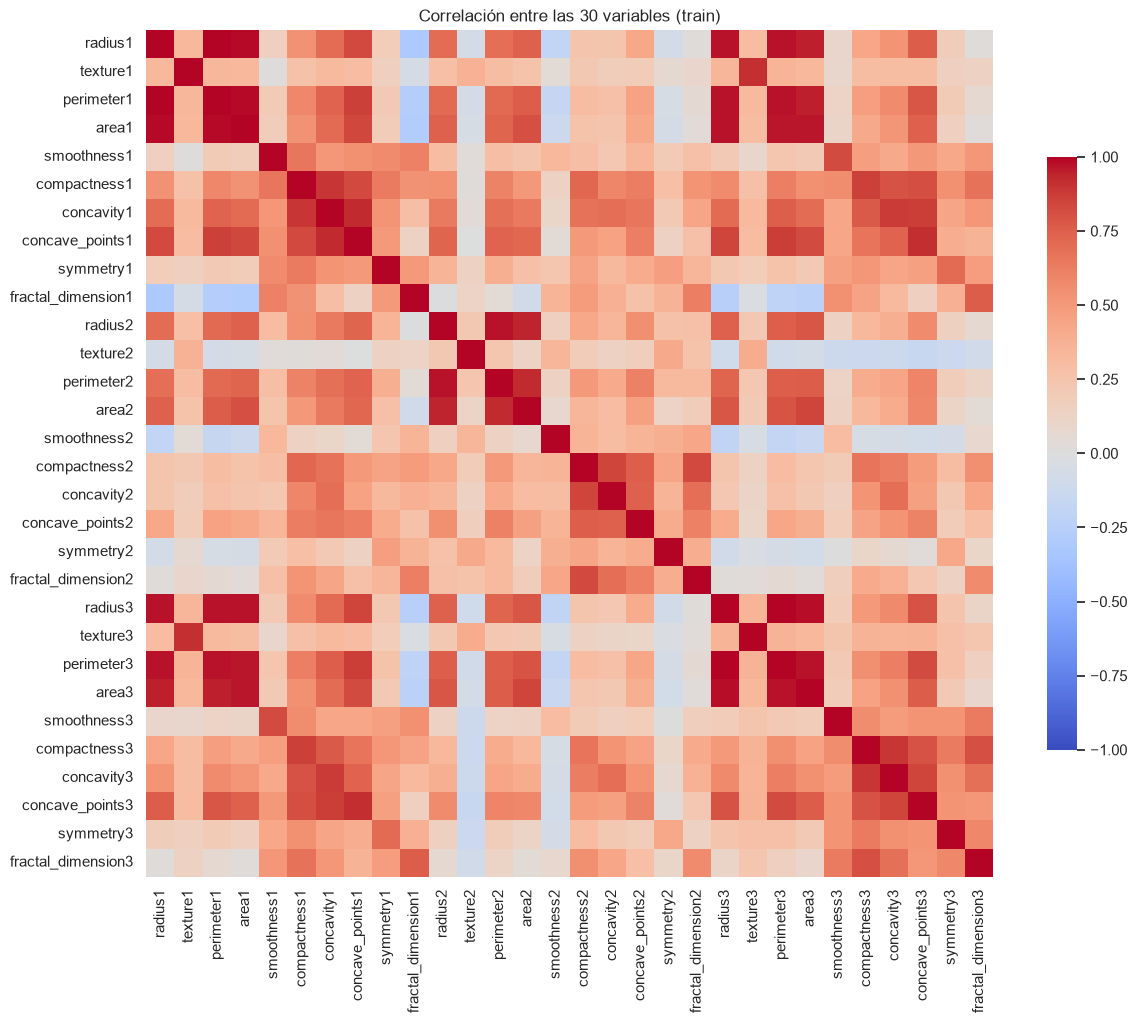

Pares con |r| > 0.90: 21


,var1,var2,corr
60,perimeter1,radius1,0.997831
680,perimeter3,radius3,0.993829
90,area1,radius1,0.987064
92,area1,perimeter1,0.986496
710,area3,radius3,0.982267
712,area3,perimeter3,0.976554
662,perimeter3,perimeter1,0.975609
600,radius3,radius1,0.974526
602,radius3,perimeter1,0.974286
660,perimeter3,radius1,0.970396


In [6]:
corr = X_train.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Correlación entre las 30 variables (train)")
plt.show()

mask = np.triu(np.ones_like(corr, dtype=bool))
pares = (corr.where(~mask).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "var1", "level_1": "var2"}))
pares_altos = pares[pares["corr"].abs() > 0.90].sort_values("corr", key=abs, ascending=False)
print(f"Pares con |r| > 0.90: {len(pares_altos)}")
display(pares_altos)

### 2.3 Redundancia entre radio, perímetro, área y textura (Actividad 2)

['radius1', 'texture1', 'perimeter1', 'area1', 'radius2', 'texture2', 'perimeter2', 'area2', 'radius3', 'texture3', 'perimeter3', 'area3']


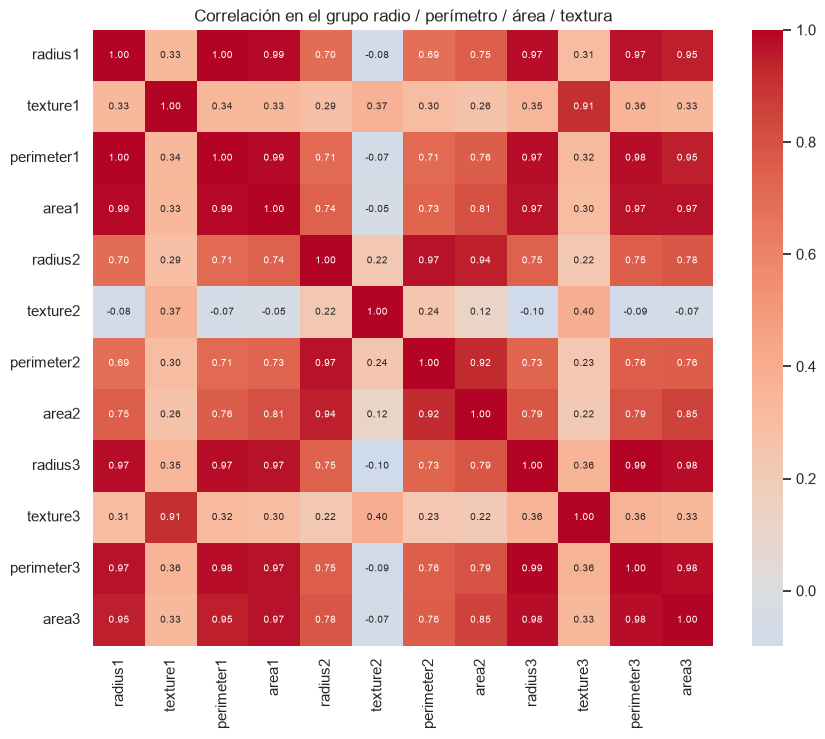

In [7]:
# Nombres típicos en este dataset: radius1, texture1, perimeter1, area1 (media),
# radius2... (error estándar), radius3... (peor valor)
cols_grupo = [c for c in X_train.columns
              if any(c.startswith(p) for p in ["radius", "perimeter", "area", "texture"])]
print(cols_grupo)

plt.figure(figsize=(10, 8))
sns.heatmap(X_train[cols_grupo].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7})
plt.title("Correlación en el grupo radio / perímetro / área / textura")
plt.show()

### 2.4 Observaciones de la exploración
- **Balance de clases:** 357 benignos (63 %) y 212 malignos (37 %); la partición estratificada mantiene esa proporción (≈37 % de malignos en train, validación y prueba).
- **Escalas:** muy distintas (`area3` llega a 4254 y `fractal_dimension2` apenas a 0,02), por lo que el escalado es obligatorio para la RNA.
- **Redundancia:** hay 21 pares con |r| > 0,90. Radio y perímetro son casi equivalentes (r = 0,998 en la versión media), y el área también está muy relacionada (r ≈ 0,99). Las versiones media y "peor valor" del mismo rasgo también están fuertemente correlacionadas (por ejemplo `perimeter1`–`perimeter3`, r = 0,976). `concavity1` y `concave_points1` también superan 0,90.
- **Textura:** `texture1` y `texture3` son poco redundantes con radio, perímetro y área, y aportan información complementaria sobre la forma de la célula.

## Actividad 3. Técnicas de selección y subconjuntos candidatos (solo con train)
ANOVA (+ filtro de redundancia), RFE con regresión logística, regularización L1 e importancia por permutación. Luego se analiza su estabilidad.

### 3.1 Funciones de selección

In [8]:
K = 10

def filtrar_redundancia(orden, corr_abs, umbral=0.90):
    elegidas = []
    for f in orden:
        if all(corr_abs.loc[f, g] < umbral for g in elegidas):
            elegidas.append(f)
    return elegidas

def sel_anova(Xt, yt, k=K, umbral=0.90):
    F, _ = f_classif(Xt, yt)
    orden = pd.Series(F, index=Xt.columns).sort_values(ascending=False).index
    return filtrar_redundancia(list(orden), Xt.corr().abs(), umbral)[:k]

def sel_mi(Xt, yt, k=K):
    mi = pd.Series(mutual_info_classif(Xt, yt, random_state=SEED), index=Xt.columns)
    return list(mi.nlargest(k).index)

def sel_rfe(Xt, yt, k=K):
    Xs = StandardScaler().fit_transform(Xt)
    rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=k, step=1).fit(Xs, yt)
    return list(Xt.columns[rfe.support_])

def sel_l1(Xt, yt):
    Xs = StandardScaler().fit_transform(Xt)
    lr = LogisticRegressionCV(Cs=10, penalty="l1", solver="liblinear",
                              cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                              scoring="f1", max_iter=5000).fit(Xs, yt)
    return list(Xt.columns[lr.coef_[0] != 0])

### 3.2 Rankings por ANOVA e información mutua

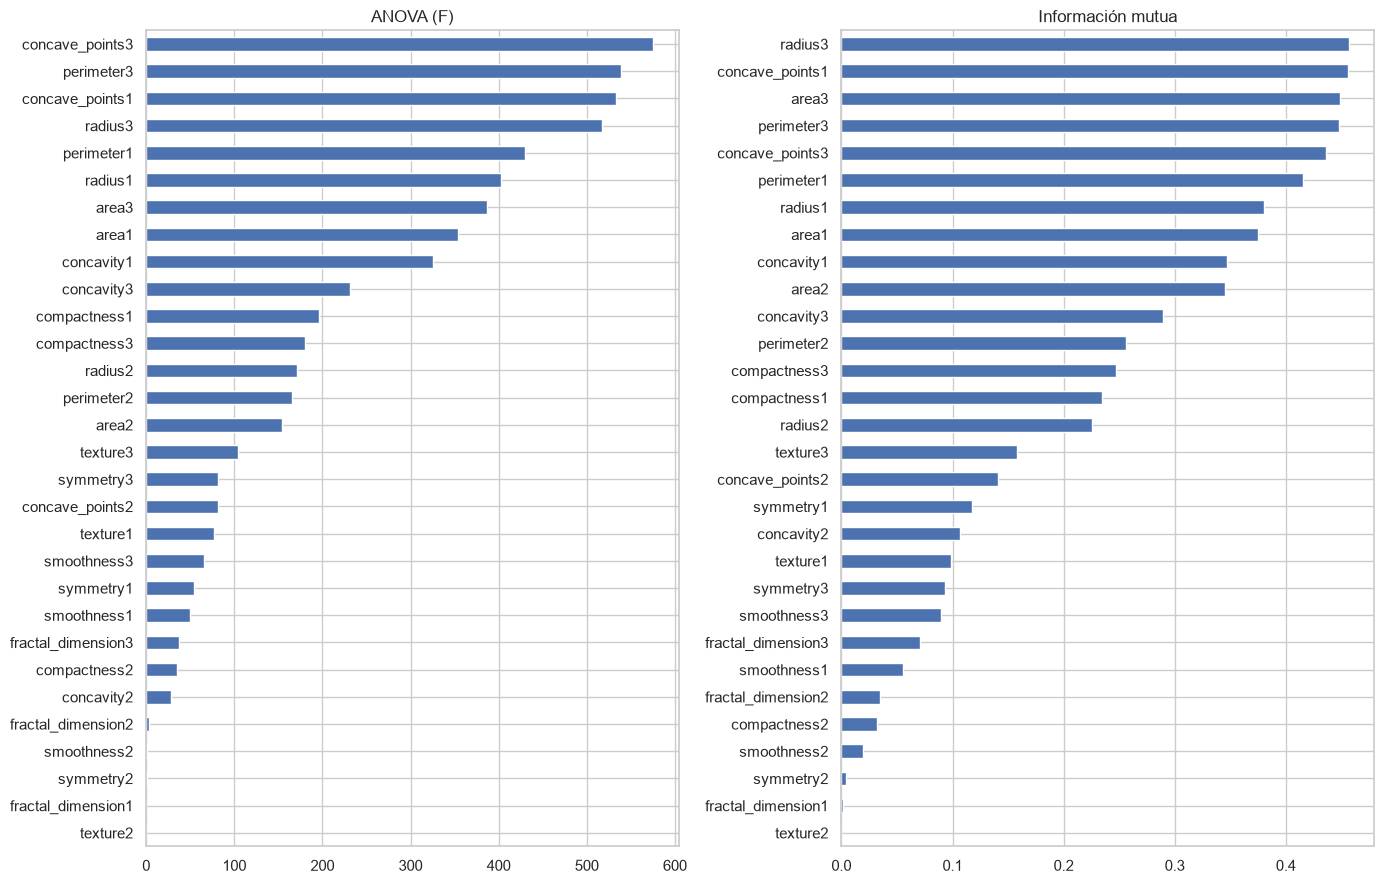

,F,p_valor
concave_points3,575.592488,4.754391e-75
perimeter3,539.160471,4.728531e-72
concave_points1,533.036776,1.551682e-71
radius3,517.155232,3.518458e-70
perimeter1,429.967442,2.945836e-62
radius1,402.342831,1.474951e-59
area3,386.710634,5.514892e-58
area1,353.575370,1.552333e-54
concavity1,325.497432,1.763639e-51
concavity3,230.803322,4.021385e-40


In [9]:
F, p = f_classif(X_train, y_train)
anova = pd.DataFrame({"F": F, "p_valor": p}, index=X_train.columns).sort_values("F", ascending=False)
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=SEED),
               index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
anova["F"].plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("ANOVA (F)")
mi.plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title("Información mutua")
plt.tight_layout(); plt.show()
display(anova.head(15))

### 3.3 Importancia por permutación (validación cruzada interna al train)

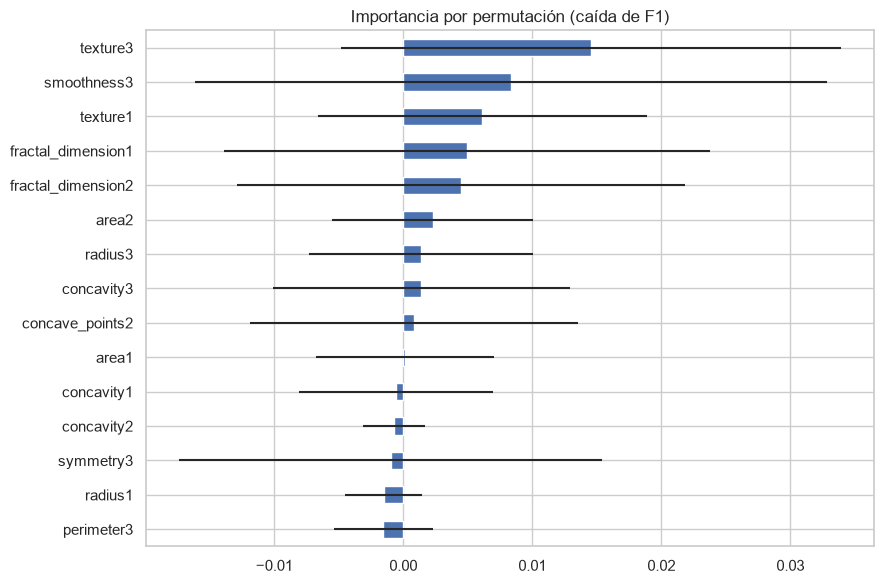

In [10]:
def crear_rna_clf(seed=SEED):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                              max_iter=1000, random_state=seed))
    ])

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
imps = []
for tr, te in skf.split(X_train, y_train):
    m = crear_rna_clf().fit(X_train.iloc[tr], y_train.iloc[tr])
    r = permutation_importance(m, X_train.iloc[te], y_train.iloc[te],
                               scoring="f1", n_repeats=10, random_state=SEED, n_jobs=-1)
    imps.append(pd.Series(r.importances_mean, index=X_train.columns))

perm = pd.concat(imps, axis=1)
perm_df = pd.DataFrame({"media": perm.mean(axis=1), "desvio": perm.std(axis=1)}) \
            .sort_values("media", ascending=False)
perm_df["media"].head(15).plot.barh(xerr=perm_df["desvio"].head(15), figsize=(9, 6))
plt.gca().invert_yaxis(); plt.title("Importancia por permutación (caída de F1)")
plt.tight_layout(); plt.show()

### 3.4 Subconjuntos candidatos

In [11]:
subset_anova = sel_anova(X_train, y_train)
subset_rfe = sel_rfe(X_train, y_train)
subset_l1 = sel_l1(X_train, y_train)
subset_perm = filtrar_redundancia(list(perm_df.index), X_train.corr().abs(), 0.90)[:K]

candidatos = {
    "Todas (30)": list(X.columns),
    "A_ANOVA_sin_redundancia": subset_anova,
    "B_RFE": subset_rfe,
    "C_L1": subset_l1,
    "D_Permutacion": subset_perm,
}
for k, v in candidatos.items():
    print(f"{k} ({len(v)}): {v}\n")

Todas (30) (30): ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']

A_ANOVA_sin_redundancia (10): ['concave_points3', 'perimeter3', 'concavity1', 'concavity3', 'compactness1', 'compactness3', 'radius2', 'texture3', 'symmetry3', 'concave_points2']

B_RFE (10): ['radius1', 'concavity1', 'concave_points1', 'radius2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3']

C_L1 (8): ['concave_points1', 'radius2', 'fractal_dimension2', 'radius3', 'texture3', 'area3', 'smoothness3', 'symmetry3']

D_Permutacion (10): ['texture3', 'smoothness3', 'fractal_dimension1', 'fractal_dimension2'

### 3.5 Estabilidad de la selección (remuestreos dentro de train)

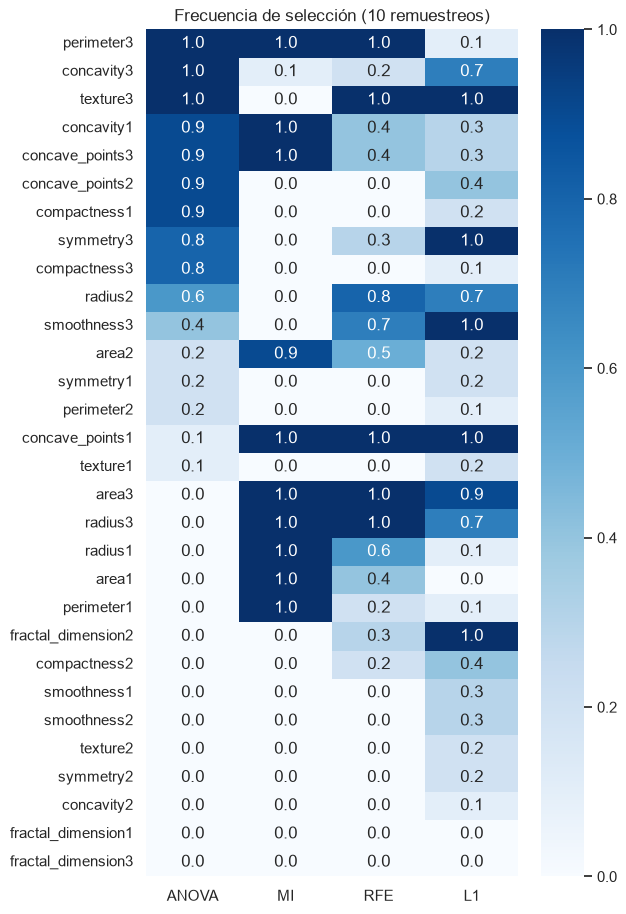

In [12]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
metodos = {"ANOVA": sel_anova, "MI": sel_mi, "RFE": sel_rfe, "L1": sel_l1}
freq = pd.DataFrame(0, index=X_train.columns, columns=list(metodos))
n_rep = 0
for tr, _ in rskf.split(X_train, y_train):
    n_rep += 1
    for nom, fn in metodos.items():
        freq.loc[fn(X_train.iloc[tr], y_train.iloc[tr]), nom] += 1

freq_pct = (freq / n_rep).sort_values(list(metodos), ascending=False)
plt.figure(figsize=(6, 11))
sns.heatmap(freq_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=1)
plt.title(f"Frecuencia de selección ({n_rep} remuestreos)")
plt.show()

## Actividad 4. Comparación con la misma arquitectura y particiones
Arquitectura (32, 16), semilla 42, escalado dentro del Pipeline y mismas particiones. Cambia solo el conjunto de variables.

**Métrica principal: recall de la clase maligna (y = 1).** Un falso negativo (maligno clasificado como benigno) puede retrasar un diagnóstico y un tratamiento, mientras que un falso positivo suele traducirse en estudios adicionales. Por eso la comparación se ordena primero por recall y falsos negativos, y después por F1, precisión, accuracy y cantidad de variables.

### 4.1 Métricas en validación: 30 variables vs. subconjuntos

In [ ]:
def metricas_clf(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "FN (malignos no detectados)": fn,
        "FP": fp,
    }

filas, modelos_val = {}, {}
for nombre, feats in candidatos.items():
    m = crear_rna_clf().fit(X_train[feats], y_train)
    pred = m.predict(X_val[feats])
    met = metricas_clf(y_val, pred)
    met["n_vars"] = len(feats)
    filas[nombre] = met
    modelos_val[nombre] = pred

res_val = pd.DataFrame(filas).T
orden_cols = ["Recall", "FN (malignos no detectados)", "F1", "Precision", "Accuracy", "FP", "n_vars"]
display(res_val[orden_cols].round(4))

### 4.2 Matrices de confusión en validación

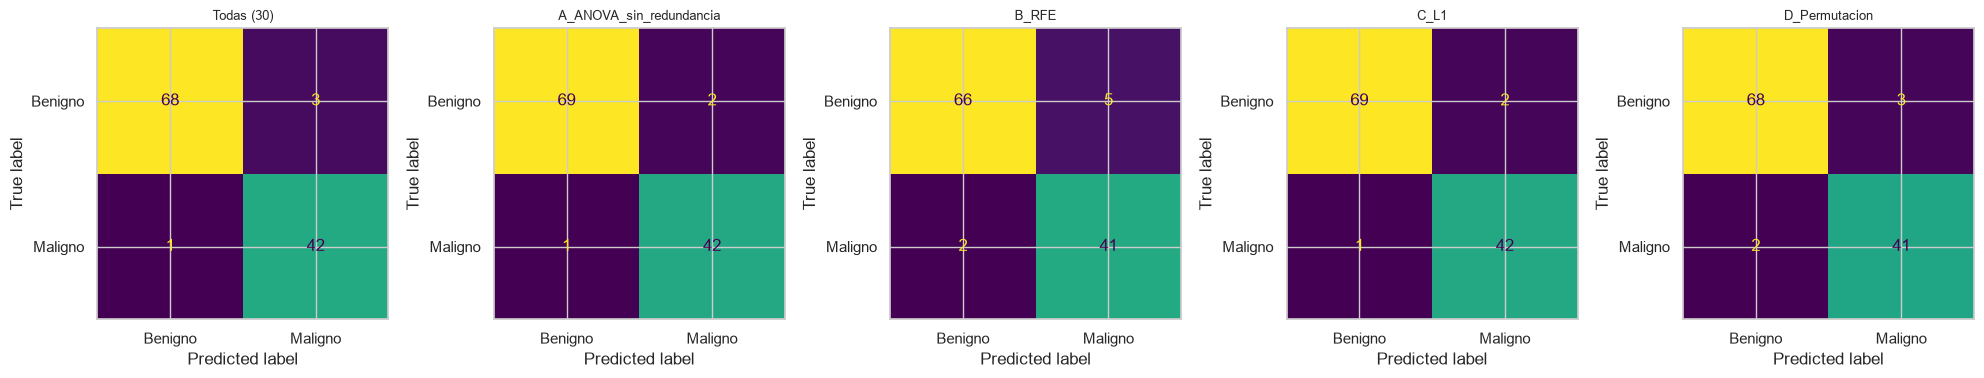

In [14]:
fig, axes = plt.subplots(1, len(candidatos), figsize=(4 * len(candidatos), 3.8))
for ax, (nombre, pred) in zip(axes, modelos_val.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                           display_labels=["Benigno", "Maligno"]).plot(ax=ax, colorbar=False)
    ax.set_title(nombre, fontsize=9)
plt.tight_layout(); plt.show()

### 4.3 Robustez frente a la semilla (análisis complementario)

In [15]:
# Mismas particiones; solo cambia la inicialización de la red.
semillas = [0, 1, 2, 3, 4]
robustez = {}
for nombre, feats in candidatos.items():
    f1s, recs = [], []
    for s in semillas:
        m = crear_rna_clf(seed=s).fit(X_train[feats], y_train)
        p = m.predict(X_val[feats])
        f1s.append(f1_score(y_val, p)); recs.append(recall_score(y_val, p))
    robustez[nombre] = {"F1_medio": np.mean(f1s), "F1_desvio": np.std(f1s),
                        "Recall_medio": np.mean(recs), "Recall_desvio": np.std(recs)}
display(pd.DataFrame(robustez).T.round(4))

,F1_medio,F1_desvio,Recall_medio,Recall_desvio
Todas (30),0.9656,0.0099,0.9767,0.0000
A_ANOVA_sin_redundancia,0.9770,0.0073,0.9860,0.0114
B_RFE,0.9327,0.0071,0.9674,0.0114
C_L1,0.9524,0.0081,0.9767,0.0000
D_Permutacion,0.9503,0.0053,0.9767,0.0000


### 4.4 Elección final y configuración congelada

In [16]:
# Criterio sugerido: menos falsos negativos, luego mayor F1, luego menos variables.
# Podés fijar el nombre a mano según tu análisis.
ranking = (res_val.drop(index="Todas (30)")
           .sort_values(["FN (malignos no detectados)", "F1", "n_vars"],
                        ascending=[True, False, True]))
nombre_final = ranking.index[0]
selected_features = candidatos[nombre_final]
print("Subconjunto final:", nombre_final)
print(f"{len(selected_features)} variables:", selected_features)

Subconjunto final: C_L1
8 variables: ['concave_points1', 'radius2', 'fractal_dimension2', 'radius3', 'texture3', 'area3', 'smoothness3', 'symmetry3']


## Actividad 7. Lista final de variables y justificación
- **Subconjunto elegido:** C_L1 (8 variables): `concave_points1`, `radius2`, `fractal_dimension2`, `radius3`, `texture3`, `area3`, `smoothness3`, `symmetry3`.
- **Desempeño en validación (prioridad: recall de la clase maligna):** con las 30 variables se obtuvo recall 0,977, 1 falso negativo, F1 0,955 y accuracy 0,965; con C_L1, recall 0,977, 1 falso negativo, F1 0,966 y accuracy 0,974. A_ANOVA obtuvo los mismos resultados, y C_L1 se eligió por usar menos variables (8 vs 10).
- **Estabilidad:** en 10 remuestreos, L1 seleccionó `concave_points1`, `fractal_dimension2`, `texture3`, `smoothness3` y `symmetry3` en el 100 % de los casos, `area3` en el 90 % y `radius2` y `radius3` en el 70 %. Entre semillas, C_L1 tuvo F1 medio de 0,952 (desvío 0,008) y recall 0,977 sin variación.
- **Redundancia (criterio práctico):** el subconjunto no incluye perímetros ni la versión media de radio y área, y evita la mayoría de los pares muy correlacionados. Sin embargo, conserva `radius3` y `area3`, que miden la misma dimensión geométrica (r = 0,98). La regularización L1 no eliminó esta redundancia, y no se cumple del todo el criterio de no incluir radio y área a la vez. Se deja señalado como limitación; una mejora posible es aplicar el filtro de redundancia sobre las variables que selecciona L1 y repetir la comparación desde la validación.
- **Complejidad del modelo:** pasar de 30 a 8 variables simplifica el modelo, reduce el costo de medición y el riesgo de sobreajuste con solo 569 muestras.
- **Interpretación de los atributos:** las variables describen los núcleos celulares medidos en imágenes digitalizadas de una punción aspirativa (el sufijo 1 es la media, el 2 el error estándar y el 3 el peor valor). `radius3` y `area3` reflejan el tamaño del núcleo en su peor caso, `concave_points1` la cantidad de entrantes en el contorno, `smoothness3` y `symmetry3` la regularidad del contorno, `texture3` la variación de grises y `fractal_dimension2` la variabilidad de la irregularidad del borde. En general, núcleos más grandes e irregulares se asocian con malignidad, por lo que el subconjunto es coherente con esa interpretación. Es una lectura general con fines educativos, no una conclusión clínica.
- **Limitación:** validación y prueba tienen 114 muestras cada una, por lo que una diferencia de uno o dos casos no es concluyente.
- **Nota de procedimiento:** en el análisis entre semillas, A_ANOVA_sin_redundancia obtuvo mejor F1 medio (0,977) que C_L1 (0,952). Se mantuvo C_L1 porque el criterio de elección (menos falsos negativos, luego F1, luego menos variables) se fijó antes de mirar la prueba.

## Actividad 6. Evaluación final en prueba (una sola vez)
Se reporta la matriz de confusión sobre `X_test` y las métricas por clase, con foco en el **recall** y el **F1** de la clase maligna (y = 1) y en los casos malignos no detectados (falsos negativos).

In [ ]:
m_todas = crear_rna_clf().fit(X_train[candidatos["Todas (30)"]], y_train)
m_sel = crear_rna_clf().fit(X_train[selected_features], y_train)

p_todas = m_todas.predict(X_test[candidatos["Todas (30)"]])
p_sel = m_sel.predict(X_test[selected_features])

res_test = pd.DataFrame({
    "Todas (30)": metricas_clf(y_test, p_todas),
    f"Selección ({nombre_final})": metricas_clf(y_test, p_sel),
}).T
res_test["n_vars"] = [30, len(selected_features)]
orden_cols = ["Recall", "FN (malignos no detectados)", "F1", "Precision", "Accuracy", "FP", "n_vars"]
display(res_test[orden_cols].round(4))

for titulo, p in [("30 variables", p_todas), (f"Selección final ({nombre_final})", p_sel)]:
    print(f"\n=== Reporte de clasificación en prueba: {titulo} ===")
    print(classification_report(y_test, p, target_names=["Benigno", "Maligno"]))
    print("Matriz de confusión (filas = real, columnas = predicho):")
    print(confusion_matrix(y_test, p))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (tit, p) in zip(axes, [("30 variables", p_todas), ("Selección final", p_sel)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
                           display_labels=["Benigno", "Maligno"]).plot(ax=ax, colorbar=False)
    ax.set_title(tit)
plt.tight_layout(); plt.show()

## Conclusión
**Por qué el recall es la métrica más importante.** En un diagnóstico oncológico el error más grave es un falso negativo: un tumor maligno clasificado como benigno puede retrasar el tratamiento. Un falso positivo, en cambio, suele llevar a estudios adicionales que lo corrigen. Por eso el recall de la clase maligna (la proporción de malignos que el modelo detecta) es la métrica principal, y el accuracy, que puede verse bien aunque se pierdan casos malignos, es secundario.

**Resultados.** En validación, el subconjunto de 8 variables igualó o superó al modelo con 30. En prueba, ambos modelos detectaron el mismo número de casos malignos: 39 de 42, con 3 falsos negativos y recall de 0,929. El modelo reducido tuvo más falsos positivos (5 vs 2), lo que explica su F1 (0,907 vs 0,940) y accuracy (0,930 vs 0,956) algo menores. Reducir las variables no empeoró la detección de malignos, pero un recall de 0,929 equivale a un 7 % de casos malignos sin detectar, lo que sería insuficiente en un contexto real. Con una prueba de 114 casos, además, la diferencia entre modelos no es concluyente. Una mejora posible, que no se probó acá, es bajar el umbral de decisión para aumentar el recall a costa de más falsos positivos.